<a href="https://colab.research.google.com/github/Yugshri/CV1/blob/main/CUSTOMERCHURNipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import os

print("My Drive folders:")
print(os.listdir('/content/drive/MyDrive'))

My Drive folders:
['01_forza7_porsche_gt2rs_02_4k_v2_noflag.jpg', 'Getting started.pdf', 'cbjeenss02.pdf', 'cbjeenss03.pdf', 'Yug sample paper maths standard', 'IMG-20200604-WA0000.jpg', 'Chapter 9  The Summer of the Beautiful White Horse.pdf', 'Ankita.vcf', 'IMG_20210604_181109_505.jpg', 'IMG_20210604_182258_253.jpg', 'chu-ohki-pcj - Sep 12, 2021 (1).pdf', 'chu-ohki-pcj - Sep 12, 2021.pdf', '↟↟.gdoc', 'Pyq relation', 'Swen', 'Raam_c_2021(1) (1)-2.docx', '770463-12-4FPE.docx', '770463-13-1FPE.docx', '771427-10-13SAQ.docx', 'IMG-20220419-WA0010.jpg', '20230405_212608.jpg', '16932911965096481068217869251195.jpg', 'S. K. Sahdev - Basic Electrical Engineering (2015, Pearson Education) - libgen.lc.pdf', 'Copy of S. K. Sahdev - Basic Electrical Engineering (2015, Pearson Education) - libgen.lc.pdf', 'Untitled form (2).gform', 'IMG-20240215-WA0009.jpg', 'UNIT I NOTES.gdoc', 'U1L8.gdoc', 'Celsius Certificate sheet.gsheet', 'Untitled document (8).gdoc', 'Winter-typography-slogan.zip (Unzipped F

In [5]:
import os

search_path = '/content/drive/MyDrive'

for root, dirs, files in os.walk(search_path):
    for file in files:
        if file in ['train.csv', 'test.csv', 'sample_submission.csv']:
            print(os.path.join(root, file))

/content/drive/MyDrive/Colab Notebooks/CUSTOMERCHURN/train.csv
/content/drive/MyDrive/Colab Notebooks/CUSTOMERCHURN/test.csv
/content/drive/MyDrive/Colab Notebooks/CUSTOMERCHURN/sample_submission.csv


In [7]:
BASE_PATH = "/content/drive/MyDrive/Colab Notebooks/CUSTOMERCHURN"

train = pd.read_csv(f"{BASE_PATH}/train.csv")
test = pd.read_csv(f"{BASE_PATH}/test.csv")
sample = pd.read_csv(f"{BASE_PATH}/sample_submission.csv")

In [8]:
import pandas as pd
import numpy as np

BASE_PATH = "/content/drive/MyDrive/Colab Notebooks/CUSTOMERCHURN"

train = pd.read_csv(f"{BASE_PATH}/train.csv")
test = pd.read_csv(f"{BASE_PATH}/test.csv")
sample = pd.read_csv(f"{BASE_PATH}/sample_submission.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)
print("Sample submission:", sample.shape)

display(train.head())

Training data: (1200, 12)
Testing data: (300, 11)
Sample submission: (300, 2)


,customer_id,age,tenure_months,monthly_charges,contract_type,internet_service,support_tickets,payment_method,autopay,data_usage_gb,late_payments_6m,churn
0,C100001,23,39,93.19,One year,Fiber,1,Credit card,Yes,120.2,0,0
1,C100002,62,19,56.06,Month-to-month,DSL,1,Electronic check,No,139.1,1,1
2,C100003,55,17,53.22,One year,DSL,0,Mailed check,Yes,105.8,2,0
3,C100004,43,24,82.11,Month-to-month,Fiber,0,Electronic check,No,130.8,2,1
4,C100005,43,44,93.75,Month-to-month,DSL,4,Bank transfer,No,75.1,0,0


In [9]:
print("Missing values:")
print(train.isnull().sum())

print("\nChurn distribution:")
print(train["churn"].value_counts())

print("\nStatistical summary:")
display(train.describe())

Missing values:
customer_id          0
age                  0
tenure_months        0
monthly_charges     27
contract_type        0
internet_service    25
support_tickets      0
payment_method       0
autopay              0
data_usage_gb        0
late_payments_6m     0
churn                0
dtype: int64

Churn distribution:
churn
1    640
0    560
Name: count, dtype: int64

Statistical summary:


,age,tenure_months,monthly_charges,support_tickets,data_usage_gb,late_payments_6m,churn
count,1200.000000,1200.000000,1173.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,46.746667,36.118333,70.719676,1.504167,177.481083,0.745833,0.533333
std,16.666702,20.890061,22.196719,1.234741,72.601197,0.837745,0.499096
min,18.000000,1.000000,20.000000,0.000000,5.000000,0.000000,0.000000
25%,32.000000,18.000000,55.760000,1.000000,129.675000,0.000000,0.000000
50%,47.000000,35.000000,71.630000,1.000000,174.700000,1.000000,1.000000
75%,61.000000,54.250000,85.440000,2.000000,222.525000,1.000000,1.000000
max,75.000000,72.000000,136.110000,8.000000,407.000000,5.000000,1.000000


In [10]:
print(
    train.groupby("contract_type")["churn"]
    .agg(["mean", "count"])
)

                    mean  count
contract_type                  
Month-to-month  0.622003    709
One year        0.461279    297
Two year        0.319588    194


In [11]:
print(
    train.groupby("payment_method")["churn"]
    .mean()
    .sort_values(ascending=False)
)


payment_method
Electronic check    0.620253
Credit card         0.534653
Bank transfer       0.511551
Mailed check        0.456835
Name: churn, dtype: float64


In [12]:
print(
    train.groupby("churn")[
        ["age", "tenure_months",
         "monthly_charges", "support_tickets",
         "data_usage_gb", "late_payments_6m"]
    ].mean()
)

             age  tenure_months  monthly_charges  support_tickets  \
churn                                                               
0      45.562500      40.235714        68.699345         1.325000   
1      47.782812      32.515625        72.503274         1.660937   

       data_usage_gb  late_payments_6m  
churn                                   
0         176.933214          0.623214  
1         177.960469          0.853125  


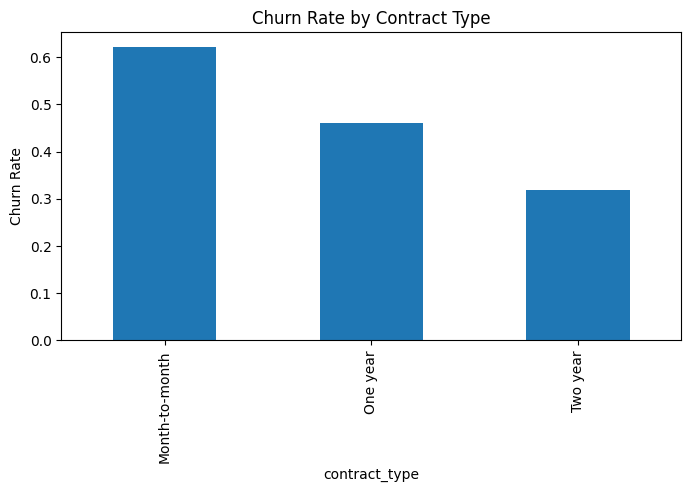

In [13]:
import matplotlib.pyplot as plt

train.groupby("contract_type")["churn"].mean().plot(
    kind="bar",
    figsize=(8, 4),
    title="Churn Rate by Contract Type"
)

plt.ylabel("Churn Rate")
plt.show()

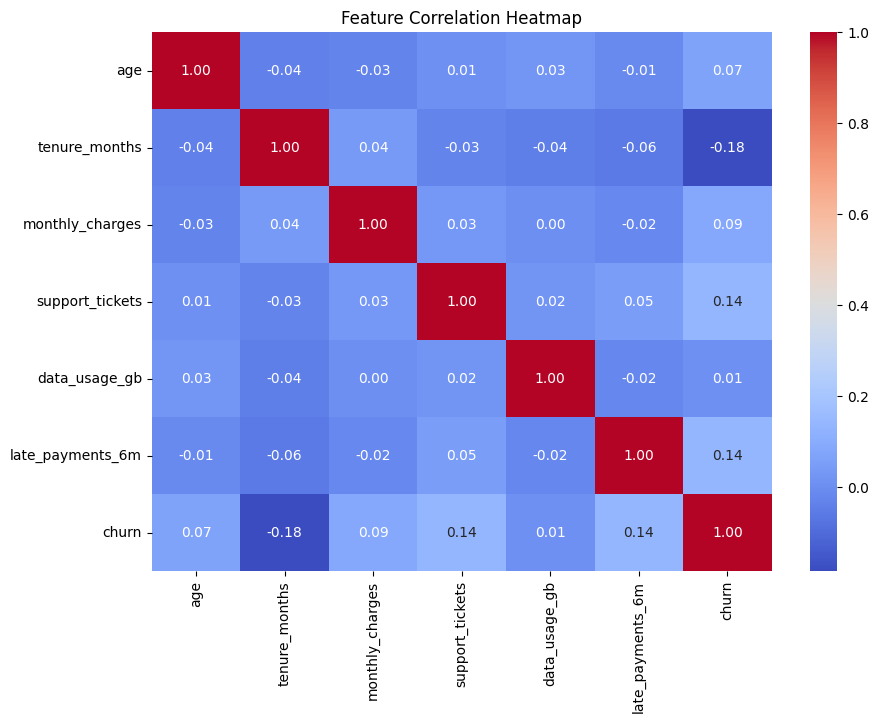

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = train.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [15]:
print("Training missing values:")
print(train.isnull().sum())

print("\nTesting missing values:")
print(test.isnull().sum())

Training missing values:
customer_id          0
age                  0
tenure_months        0
monthly_charges     27
contract_type        0
internet_service    25
support_tickets      0
payment_method       0
autopay              0
data_usage_gb        0
late_payments_6m     0
churn                0
dtype: int64

Testing missing values:
customer_id          0
age                  0
tenure_months        0
monthly_charges     10
contract_type        0
internet_service     5
support_tickets      0
payment_method       0
autopay              0
data_usage_gb        0
late_payments_6m     0
dtype: int64


In [16]:
train_clean = train.copy()
test_clean = test.copy()

In [17]:
# Numerical column
median_value = train_clean["monthly_charges"].median()

# Categorical column
mode_value = train_clean["internet_service"].mode()[0]

print("Median:", median_value)
print("Mode:", mode_value)

Median: 71.63
Mode: Fiber


In [18]:
train_clean["monthly_charges"] = (
    train_clean["monthly_charges"].fillna(median_value)
)

test_clean["monthly_charges"] = (
    test_clean["monthly_charges"].fillna(median_value)
)

train_clean["internet_service"] = (
    train_clean["internet_service"].fillna(mode_value)
)

test_clean["internet_service"] = (
    test_clean["internet_service"].fillna(mode_value)
)

In [19]:
print("Training missing values:")
print(train_clean.isnull().sum())

print("\nTesting missing values:")
print(test_clean.isnull().sum())

Training missing values:
customer_id         0
age                 0
tenure_months       0
monthly_charges     0
contract_type       0
internet_service    0
support_tickets     0
payment_method      0
autopay             0
data_usage_gb       0
late_payments_6m    0
churn               0
dtype: int64

Testing missing values:
customer_id         0
age                 0
tenure_months       0
monthly_charges     0
contract_type       0
internet_service    0
support_tickets     0
payment_method      0
autopay             0
data_usage_gb       0
late_payments_6m    0
dtype: int64


In [20]:
from sklearn.preprocessing import OneHotEncoder

In [21]:
categorical_cols = [
    "contract_type",
    "internet_service",
    "payment_method",
    "autopay"
]

In [22]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [23]:
encoder.fit(train_clean[categorical_cols])

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [24]:
train_encoded = encoder.transform(
    train_clean[categorical_cols]
)

test_encoded = encoder.transform(
    test_clean[categorical_cols]
)

In [25]:
encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

print(encoded_columns)

['contract_type_Month-to-month' 'contract_type_One year'
 'contract_type_Two year' 'internet_service_DSL' 'internet_service_Fiber'
 'internet_service_No' 'payment_method_Bank transfer'
 'payment_method_Credit card' 'payment_method_Electronic check'
 'payment_method_Mailed check' 'autopay_No' 'autopay_Yes']


In [26]:
train_cat_df = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=train_clean.index
)

test_cat_df = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=test_clean.index
)

In [27]:
numerical_cols = [
    col for col in train_clean.select_dtypes(
        include="number"
    ).columns
    if col != "churn"
]

In [28]:
X_train = pd.concat(
    [
        train_clean[numerical_cols],
        train_cat_df
    ],
    axis=1
)

X_test = pd.concat(
    [
        test_clean[numerical_cols],
        test_cat_df
    ],
    axis=1
)

y_train = train_clean["churn"]

In [29]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

display(X_train.head())

X_train: (1200, 18)
X_test: (300, 18)


,age,tenure_months,monthly_charges,support_tickets,data_usage_gb,late_payments_6m,contract_type_Month-to-month,contract_type_One year,contract_type_Two year,internet_service_DSL,internet_service_Fiber,internet_service_No,payment_method_Bank transfer,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check,autopay_No,autopay_Yes
0,23,39,93.19,1,120.2,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,62,19,56.06,1,139.1,1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,55,17,53.22,0,105.8,2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,43,24,82.11,0,130.8,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,43,44,93.75,4,75.1,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [30]:
print(encoder.get_feature_names_out(categorical_cols))
print("Train encoded shape:", train_encoded.shape)
print("Test encoded shape:", test_encoded.shape)

['contract_type_Month-to-month' 'contract_type_One year'
 'contract_type_Two year' 'internet_service_DSL' 'internet_service_Fiber'
 'internet_service_No' 'payment_method_Bank transfer'
 'payment_method_Credit card' 'payment_method_Electronic check'
 'payment_method_Mailed check' 'autopay_No' 'autopay_Yes']
Train encoded shape: (1200, 12)
Test encoded shape: (300, 12)


In [31]:
# Combine numerical and categorical features
X_train = pd.concat(
    [train_clean[numerical_cols], train_cat_df],
    axis=1
)

X_test = pd.concat(
    [test_clean[numerical_cols], test_cat_df],
    axis=1
)

# Target variable
y_train = train_clean["churn"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

X_train shape: (1200, 18)
X_test shape: (300, 18)
y_train shape: (1200,)

Missing values in X_train: 0
Missing values in X_test: 0


In [32]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training features:", X_train_split.shape)
print("Validation features:", X_val.shape)
print("Training labels:", y_train_split.shape)
print("Validation labels:", y_val.shape)

Training features: (960, 18)
Validation features: (240, 18)
Training labels: (960,)
Validation labels: (240,)


In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_split, y_train_split)

print("Model training completed!")

Model training completed!


In [34]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_val, y_pred))

Accuracy: 0.6791666666666667

Classification Report:

              precision    recall  f1-score   support

           0       0.68      0.59      0.63       112
           1       0.68      0.76      0.72       128

    accuracy                           0.68       240
   macro avg       0.68      0.67      0.67       240
weighted avg       0.68      0.68      0.68       240



[[66 46]
 [31 97]]


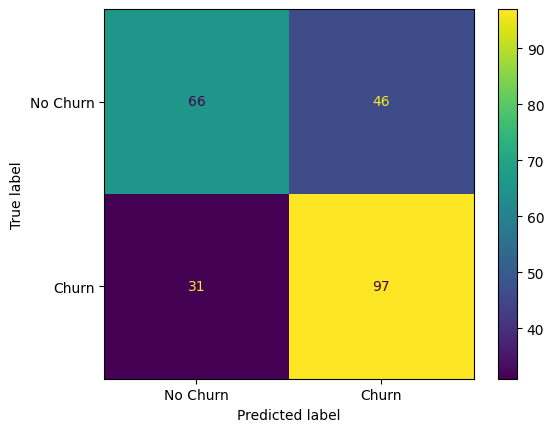

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.show()

In [36]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_val)[:, 1]

print("ROC-AUC:", roc_auc_score(y_val, y_prob))

ROC-AUC: 0.73779296875


In [37]:
# Get churn probabilities
y_prob = model.predict_proba(X_val)[:, 1]

# Use a lower threshold
y_pred_40 = (y_prob >= 0.40).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_40))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_40))

Confusion Matrix:
[[ 43  69]
 [ 16 112]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.38      0.50       112
           1       0.62      0.88      0.72       128

    accuracy                           0.65       240
   macro avg       0.67      0.63      0.61       240
weighted avg       0.67      0.65      0.62       240



In [38]:
import pandas as pd

results = pd.DataFrame({
    "Actual_Churn": y_val.values,
    "Churn_Probability": y_prob,
    "Predicted_050": y_pred,
    "Predicted_040": y_pred_40
})

results.head(10)

,Actual_Churn,Churn_Probability,Predicted_050,Predicted_040
0,1,0.398791,0,0
1,1,0.463277,0,1
2,0,0.257705,0,0
3,0,0.427727,0,1
4,0,0.792666,1,1
5,1,0.760900,1,1
6,1,0.549677,1,1
7,1,0.594708,1,1
8,1,0.445544,0,1
9,0,0.324766,0,0


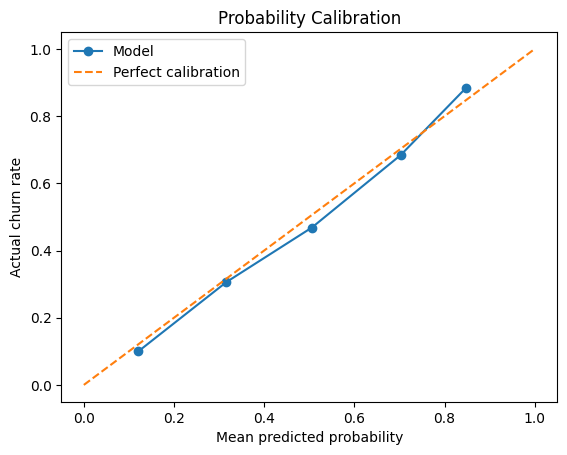

In [39]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_val,
    y_prob,
    n_bins=5
)

plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual churn rate")
plt.title("Probability Calibration")
plt.legend()
plt.show()

In [40]:
# Separate features and target
X = train.drop(columns=["churn", "customer_id"])
y = train["churn"]

X_test_final = test.drop(columns=["customer_id"])

# Identify column types
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical:", categorical_cols)
print("Numerical:", numerical_cols)

Categorical: ['contract_type', 'internet_service', 'payment_method', 'autopay']
Numerical: ['age', 'tenure_months', 'monthly_charges', 'support_tickets', 'data_usage_gb', 'late_payments_6m']


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [42]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [43]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [44]:
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [46]:
print("Raw X columns:")
print(X.columns.tolist())

print("\nOld split columns:")
print(X_train_split.columns.tolist())

Raw X columns:
['age', 'tenure_months', 'monthly_charges', 'contract_type', 'internet_service', 'support_tickets', 'payment_method', 'autopay', 'data_usage_gb', 'late_payments_6m']

Old split columns:
['age', 'tenure_months', 'monthly_charges', 'support_tickets', 'data_usage_gb', 'late_payments_6m', 'contract_type_Month-to-month', 'contract_type_One year', 'contract_type_Two year', 'internet_service_DSL', 'internet_service_Fiber', 'internet_service_No', 'payment_method_Bank transfer', 'payment_method_Credit card', 'payment_method_Electronic check', 'payment_method_Mailed check', 'autopay_No', 'autopay_Yes']


In [47]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train_split.shape)
print("Validation:", X_val.shape)

Train: (960, 10)
Validation: (240, 10)


In [49]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Build a fresh model pipeline
churn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [50]:
churn_pipeline.fit(X_train_split, y_train_split)

print("Training completed!")
print(
    "Preprocessor fitted:",
    hasattr(churn_pipeline.named_steps["preprocessor"], "transformers_")
)

Training completed!
Preprocessor fitted: True


In [51]:
y_pred_pipeline = churn_pipeline.predict(X_val)

y_prob_pipeline = churn_pipeline.predict_proba(X_val)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [52]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

print("Accuracy:", accuracy_score(y_val, y_pred_pipeline))
print("ROC-AUC:", roc_auc_score(y_val, y_prob_pipeline))
print(classification_report(y_val, y_pred_pipeline))

Accuracy: 0.6791666666666667
ROC-AUC: 0.7384905133928571
              precision    recall  f1-score   support

           0       0.68      0.59      0.63       112
           1       0.68      0.76      0.72       128

    accuracy                           0.68       240
   macro avg       0.68      0.67      0.67       240
weighted avg       0.68      0.68      0.68       240



In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train_split, y_train_split)

rf_pred = rf_pipeline.predict(X_val)
rf_prob = rf_pipeline.predict_proba(X_val)[:, 1]

In [54]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

print("Random Forest Accuracy:",
      accuracy_score(y_val, rf_pred))

print("Random Forest ROC-AUC:",
      roc_auc_score(y_val, rf_prob))

print(classification_report(y_val, rf_pred))

Random Forest Accuracy: 0.6416666666666667
Random Forest ROC-AUC: 0.6911969866071429
              precision    recall  f1-score   support

           0       0.62      0.61      0.61       112
           1       0.66      0.67      0.67       128

    accuracy                           0.64       240
   macro avg       0.64      0.64      0.64       240
weighted avg       0.64      0.64      0.64       240



In [57]:
print("LOGISTIC REGRESSION")

print("Train accuracy:",
      accuracy_score(y_train_split, lr_train_pred))

print("Validation accuracy:",
      accuracy_score(y_val, y_pred_pipeline))

print("Train ROC-AUC:",
      roc_auc_score(y_train_split, lr_train_prob))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_prob_pipeline))


print("\nRANDOM FOREST")

print("Train accuracy:",
      accuracy_score(y_train_split, rf_train_pred))

print("Validation accuracy:",
      accuracy_score(y_val, rf_pred))

print("Train ROC-AUC:",
      roc_auc_score(y_train_split, rf_train_prob))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, rf_prob))

LOGISTIC REGRESSION


NameError: name 'lr_train_pred' is not defined

In [58]:
# Logistic Regression predictions
lr_train_pred = churn_pipeline.predict(X_train_split)
lr_train_prob = churn_pipeline.predict_proba(X_train_split)[:, 1]

# Random Forest predictions
rf_train_pred = rf_pipeline.predict(X_train_split)
rf_train_prob = rf_pipeline.predict_proba(X_train_split)[:, 1]

print("All training predictions generated!")

All training predictions generated!


In [59]:
print("LOGISTIC REGRESSION")

print("Train accuracy:",
      accuracy_score(y_train_split, lr_train_pred))

print("Validation accuracy:",
      accuracy_score(y_val, y_pred_pipeline))

print("Train ROC-AUC:",
      roc_auc_score(y_train_split, lr_train_prob))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_prob_pipeline))


print("\nRANDOM FOREST")

print("Train accuracy:",
      accuracy_score(y_train_split, rf_train_pred))

print("Validation accuracy:",
      accuracy_score(y_val, rf_pred))

print("Train ROC-AUC:",
      roc_auc_score(y_train_split, rf_train_prob))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, rf_prob))

LOGISTIC REGRESSION
Train accuracy: 0.6625
Validation accuracy: 0.6791666666666667
Train ROC-AUC: 0.7306300571986608
Validation ROC-AUC: 0.7384905133928571

RANDOM FOREST
Train accuracy: 0.9770833333333333
Validation accuracy: 0.6416666666666667
Train ROC-AUC: 0.9975411551339285
Validation ROC-AUC: 0.6911969866071429


In [60]:
rf_tuned = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        min_samples_split=15,
        min_samples_leaf=8,
        max_features="sqrt",
        random_state=42,
        class_weight="balanced"
    ))
])

rf_tuned.fit(X_train_split, y_train_split)

rf_tuned_pred = rf_tuned.predict(X_val)
rf_tuned_prob = rf_tuned.predict_proba(X_val)[:, 1]

In [61]:
print("Tuned Random Forest Accuracy:",
      accuracy_score(y_val, rf_tuned_pred))

print("Tuned Random Forest ROC-AUC:",
      roc_auc_score(y_val, rf_tuned_prob))

print(classification_report(y_val, rf_tuned_pred))

Tuned Random Forest Accuracy: 0.675
Tuned Random Forest ROC-AUC: 0.7331891741071429
              precision    recall  f1-score   support

           0       0.65      0.64      0.65       112
           1       0.69      0.70      0.70       128

    accuracy                           0.68       240
   macro avg       0.67      0.67      0.67       240
weighted avg       0.67      0.68      0.67       240



In [63]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "f1": "f1"
}

# Logistic Regression
lr_cv = cross_validate(
    churn_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Tuned Random Forest
rf_cv = cross_validate(
    rf_tuned,
    X,
    y,
    cv=cv,
    scoring=scoring
)

print("LOGISTIC REGRESSION")
print("Mean Accuracy:", lr_cv["test_accuracy"].mean())
print("Mean ROC-AUC:", lr_cv["test_roc_auc"].mean())
print("Mean F1:", lr_cv["test_f1"].mean())

print("\nTUNED RANDOM FOREST")
print("Mean Accuracy:", rf_cv["test_accuracy"].mean())
print("Mean ROC-AUC:", rf_cv["test_roc_auc"].mean())
print("Mean F1:", rf_cv["test_f1"].mean())

LOGISTIC REGRESSION
Mean Accuracy: 0.6516666666666666
Mean ROC-AUC: 0.7164760044642857
Mean F1: 0.6826305843428788

TUNED RANDOM FOREST
Mean Accuracy: 0.6466666666666667
Mean ROC-AUC: 0.7020647321428571
Mean F1: 0.6630318733323682


In [64]:

# Train using all labelled records
churn_pipeline.fit(X, y)

print("Final Logistic Regression model trained!")

Final Logistic Regression model trained!


In [65]:
# Predict probability of churn
test_probabilities = churn_pipeline.predict_proba(X_test_final)[:, 1]

print("Number of predictions:", len(test_probabilities))
print("First 10 probabilities:", test_probabilities[:10])

Number of predictions: 300
First 10 probabilities: [0.59238689 0.56422998 0.28733794 0.37208094 0.4104897  0.36032991
 0.47477679 0.69845164 0.72023054 0.33809934]


In [66]:
print(sample.head())
print(sample.columns.tolist())

  customer_id  churn
0     C101201      0
1     C101202      0
2     C101203      0
3     C101204      0
4     C101205      0
['customer_id', 'churn']


In [67]:
submission = sample.copy()

submission["churn"] = test_probabilities

print(submission.head())
print("Submission shape:", submission.shape)

  customer_id     churn
0     C101201  0.592387
1     C101202  0.564230
2     C101203  0.287338
3     C101204  0.372081
4     C101205  0.410490
Submission shape: (300, 2)


In [68]:
submission.to_csv("submission.csv", index=False)

print("Submission file created successfully!")

Submission file created successfully!


In [69]:
import numpy as np

assert submission.shape == (len(test), 2)
assert submission.columns.tolist() == ["customer_id", "churn"]
assert submission["customer_id"].equals(sample["customer_id"])
assert submission["churn"].notna().all()
assert submission["churn"].between(0, 1).all()

print("All submission checks passed!")

All submission checks passed!
